In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/NuInsSeg.zip"
extract_path = "/content/NuInsSeg"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted successfully!")


✅ Dataset extracted successfully!


In [ ]:
!pip install albumentations==1.4.3 tqdm --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 kB 14.8 MB/s eta 0:00:00


In [ ]:
import os, glob, random
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm import tqdm
import albumentations as A
from pathlib import Path


In [ ]:
class NucleiDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transforms=None):
        self.images = image_paths
        self.masks  = mask_paths
        self.transforms = transforms

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.images[idx]).convert('RGB'))
        mask = np.array(Image.open(self.masks[idx]).convert('L'))

        mask = (mask > 127).astype('uint8')

        if self.transforms:
            aug = self.transforms(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']

        img = img.transpose(2,0,1).astype('float32') / 255.0
        mask = np.expand_dims(mask,0).astype('float32')

        return torch.tensor(img), torch.tensor(mask)


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)
        self.center = DoubleConv(base*8, base*16)

        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        self.dec4 = DoubleConv(base*16 + base*8, base*8)
        self.dec3 = DoubleConv(base*8 + base*4, base*4)
        self.dec2 = DoubleConv(base*4 + base*2, base*2)
        self.dec1 = DoubleConv(base*2 + base, base)

        self.final = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        c  = self.center(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up(c), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))

        return self.final(d1)


In [ ]:
def dice_loss(pred, target, eps=1e-6):
    pred = torch.sigmoid(pred)
    inter = (pred * target).sum()
    return 1 - (2 * inter + eps) / (pred.sum() + target.sum() + eps)


In [ ]:
base_path = Path("/content/NuInsSeg")

all_images = []
all_masks  = []

for organ_folder in base_path.iterdir():
    if organ_folder.is_dir():
        img_dir = organ_folder / "tissue images"
        mask_dir = organ_folder / "mask binary"

        if img_dir.exists() and mask_dir.exists():
            imgs = sorted(glob.glob(str(img_dir / "*.png")))
            masks = sorted(glob.glob(str(mask_dir / "*.png")))

            all_images.extend(imgs)
            all_masks.extend(masks)

print(f"✅ Total images found: {len(all_images)}")


✅ Total images found: 665


In [ ]:
pairs = list(zip(all_images, all_masks))
random.shuffle(pairs)

split = int(0.8 * len(pairs))
train_pairs = pairs[:split]
val_pairs   = pairs[split:]

train_imgs, train_masks = zip(*train_pairs)
val_imgs, val_masks     = zip(*val_pairs)

print(f"Train: {len(train_imgs)} | Val: {len(val_imgs)}")


Train: 532 | Val: 133


In [ ]:
train_tf = A.Compose([
    A.Resize(256,256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5)
])

val_tf = A.Compose([
    A.Resize(256,256)
])

train_ds = NucleiDataset(train_imgs, train_masks, train_tf)
val_ds   = NucleiDataset(val_imgs, val_masks, val_tf)

train_dl = DataLoader(train_ds, batch_size=4, shuffle=True)
val_dl   = DataLoader(val_ds, batch_size=4)


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

best_dice = 0

for epoch in range(50):
    print(f"\n🔹 Epoch {epoch+1}/50")
    model.train()
    train_loss = 0

    for imgs, masks in tqdm(train_dl):
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = dice_loss(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    print(f"Train Loss: {train_loss/len(train_dl):.4f}")

    # Validation
    model.eval()
    val_dice = 0

    with torch.no_grad():
        for imgs, masks in val_dl:
            imgs, masks = imgs.to(device), masks.to(device)
            outputs = model(imgs)
            dice = 1 - dice_loss(outputs, masks)
            val_dice += dice.item()

    avg_dice = val_dice / len(val_dl)
    print(f"Val Dice: {avg_dice:.4f}")

    if avg_dice > best_dice:
        best_dice = avg_dice
        torch.save(model.state_dict(), "/content/best_unet_nuinsseg.pth")
        print("✅ Saved Best Model")



🔹 Epoch 1/50


100%|██████████| 133/133 [00:21<00:00,  6.26it/s]


Train Loss: 0.6322
Val Dice: 0.4141
✅ Saved Best Model

🔹 Epoch 2/50


100%|██████████| 133/133 [00:19<00:00,  6.91it/s]


Train Loss: 0.5585
Val Dice: 0.4350
✅ Saved Best Model

🔹 Epoch 3/50


...

Train Loss: 0.1537
Val Dice: 0.8197

🔹 Epoch 49/50


100%|██████████| 133/133 [00:19<00:00,  6.87it/s]


Train Loss: 0.1559
Val Dice: 0.8160

🔹 Epoch 50/50


100%|██████████| 133/133 [00:19<00:00,  6.76it/s]


Train Loss: 0.1603
Val Dice: 0.8260


In [ ]:
from google.colab import files
files.download("/content/best_unet_nuinsseg.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch
import numpy as np
import random
import cv2
import matplotlib.pyplot as plt
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet()
model.load_state_dict(torch.load("/content/best_unet_nuinsseg.pth", map_location=device))
model.to(device)
model.eval()

print("✅ Model loaded successfully!")


✅ Model loaded successfully!


In [ ]:
def iou_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).astype(np.float32)
    target = (target > 0.5).astype(np.float32)

    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection

    return (intersection + smooth) / (union + smooth)

def dice_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).astype(np.float32)
    target = (target > 0.5).astype(np.float32)

    intersection = (pred * target).sum()

    return (2 * intersection + smooth) / (pred.sum() + target.sum() + smooth)


In [ ]:
from pathlib import Path
import glob

base_path = Path("/content/NuInsSeg")

all_images = []
all_masks = []

for organ_folder in base_path.iterdir():
    if organ_folder.is_dir():
        img_dir = organ_folder / "tissue images"
        mask_dir = organ_folder / "mask binary"

        if img_dir.exists() and mask_dir.exists():
            imgs = sorted(glob.glob(str(img_dir / "*.png")))
            masks = sorted(glob.glob(str(mask_dir / "*.png")))

            all_images.extend(imgs)
            all_masks.extend(masks)

print(f"✅ Total samples available: {len(all_images)}")


✅ Total samples available: 665


In [ ]:
num_samples = 4
indices = random.sample(range(len(all_images)), num_samples)


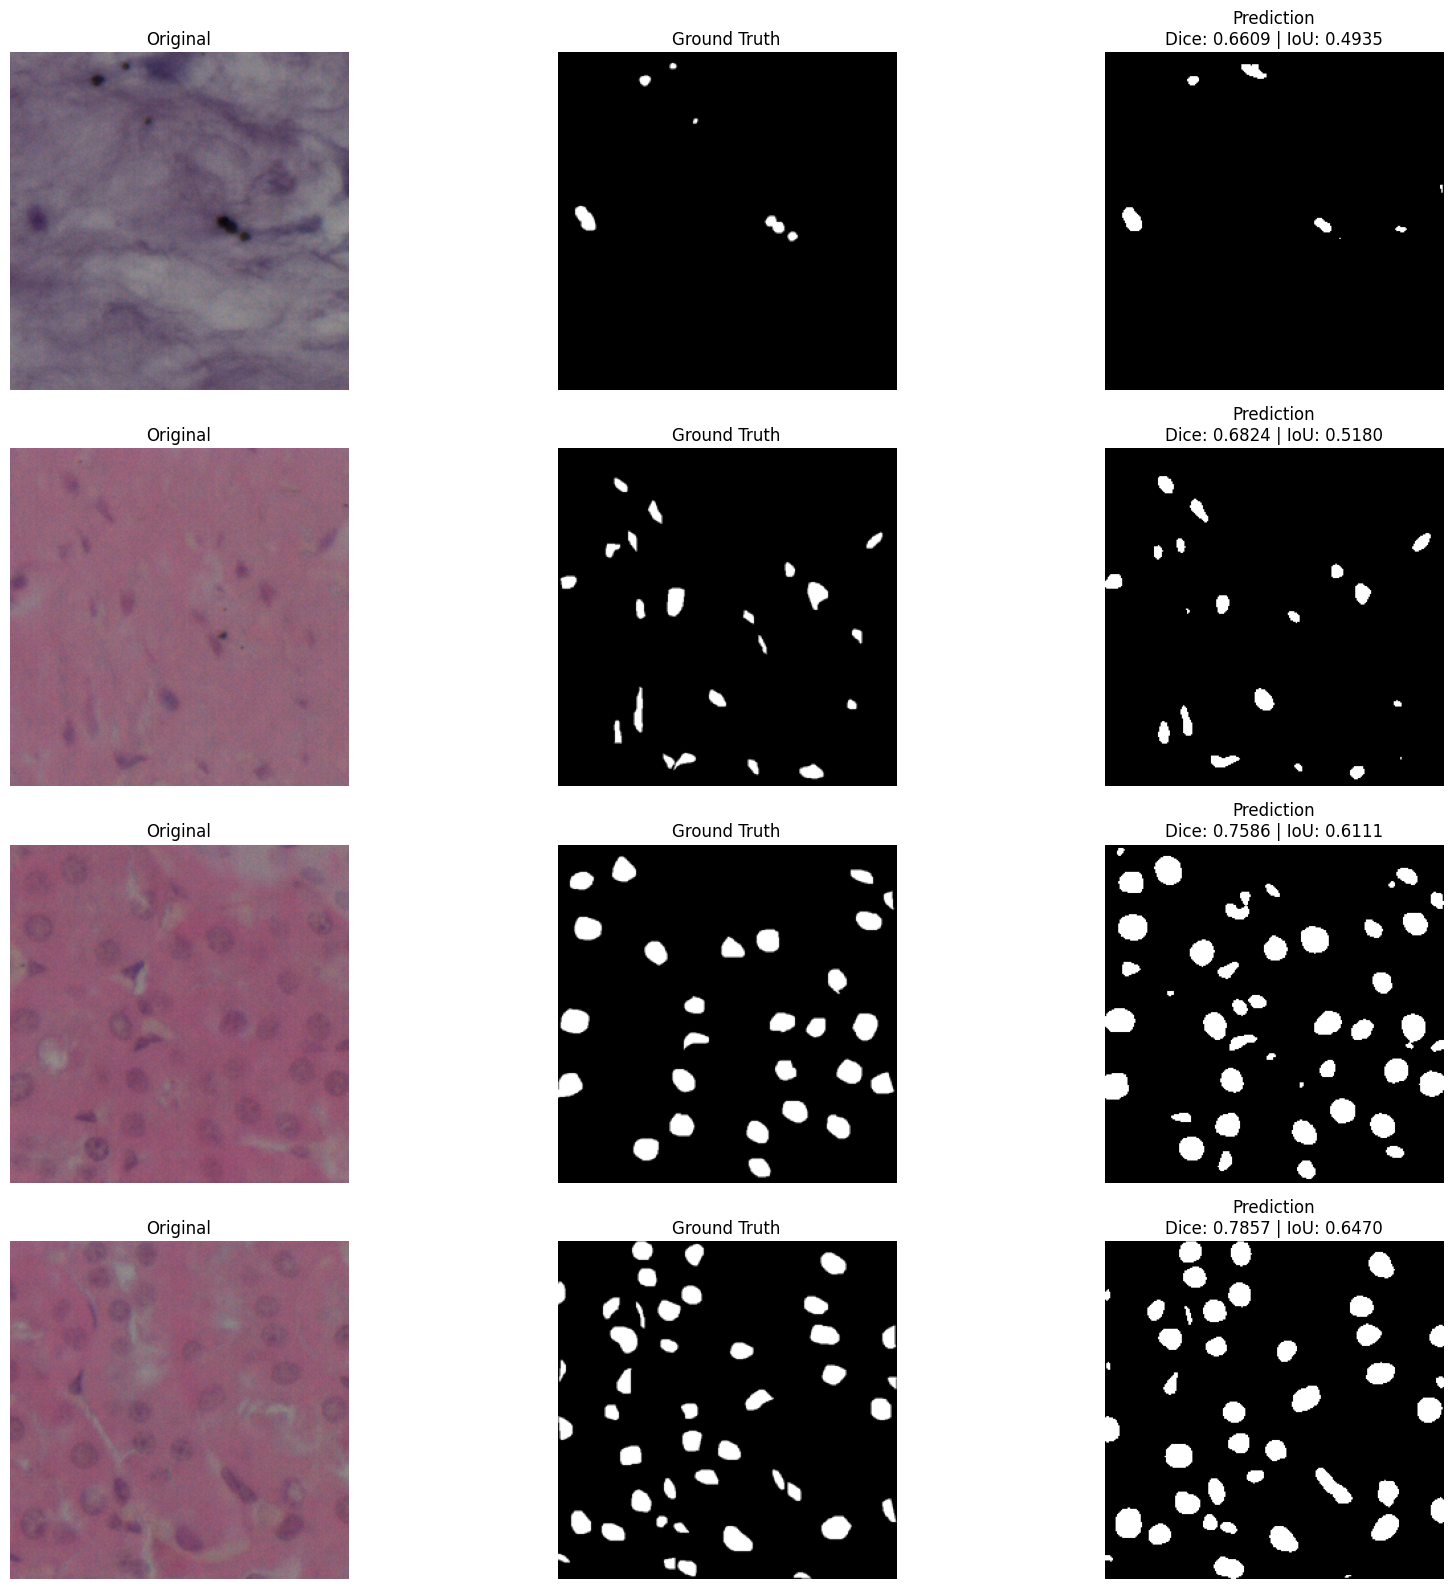

In [ ]:
plt.figure(figsize=(18, 4*num_samples))

for i, idx in enumerate(indices):

    img_path = all_images[idx]
    mask_path = all_masks[idx]

    # Load image
    img_orig = Image.open(img_path).convert('RGB')
    mask_gt = Image.open(mask_path).convert('L')

    orig_w, orig_h = img_orig.size

    # Resize for model
    img_resized = img_orig.resize((256,256))
    img_np = np.array(img_resized).astype('float32') / 255.0
    img_tensor = torch.tensor(img_np.transpose(2,0,1)).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        pred = model(img_tensor)
        pred = torch.sigmoid(pred)[0,0].cpu().numpy()

    # Resize GT
    mask_gt_resized = mask_gt.resize((256,256))
    gt_np = np.array(mask_gt_resized).astype('float32') / 255.0

    # Binary prediction
    pred_bin = (pred > 0.5).astype(np.uint8)

    # Metrics
    dice = dice_score(pred_bin, gt_np)
    iou = iou_score(pred_bin, gt_np)

    # Plot
    plt.subplot(num_samples, 3, i*3 + 1)
    plt.imshow(img_orig)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(num_samples, 3, i*3 + 2)
    plt.imshow(gt_np, cmap='gray')
    plt.title("Ground Truth")
    plt.axis('off')

    plt.subplot(num_samples, 3, i*3 + 3)
    plt.imshow(pred_bin, cmap='gray')
    plt.title(f"Prediction\nDice: {dice:.4f} | IoU: {iou:.4f}")
    plt.axis('off')

plt.tight_layout()
plt.show()
